# Feature sweep — one column at a time

Goal: walk through **every column** of the challenge files, one per section. For each: what it
actually is in plain words, order statistics, and a picture of its distribution — over the 2025
training data and, where meaningful, side by side with the Jan/Jul 2026 `ranking.parquet`.

Data comes from the parquet mirror in `../data/` (see `README.md`). Sections get appended as we go.

**Roadmap** (column order of the files) —
`MVT_ID_mvt` ✅ · `FLIGHT_ID_mvt` ✅ · `FLIGHT_mvt` · `FLIGHT_RULE_mvt` · `ADEP_mvt` · `ADES_mvt` ·
`PHASE_mvt` · `MVT_TIME_UTC_mvt` · `BLOCK_TIME_UTC_mvt` · `SCHED_TIME_UTC_mvt` ·
`AIRCRAFT_TYPE_mvt` · `RUNWAY_mvt` · `STAND_mvt` · `TAXITIME_SEC_mvt` (target) · `LOBT_flt` ·
`CALLSIGN_flt` · `ADEP_flt` · `ADES_flt` · `ADES_FILED_flt` · `MARKET_SEGMENT_flt` · `IOBT_flt` ·
`FLIGHT_RULE_flt` · `FLIGHT_TYPE_flt` · `AIRCRAFT_TYPE_flt` · `WK_TBL_CAT_flt` ·
`AIRCRAFT_OPERATOR_flt` · `EOBT_1_flt` · `ARVT_1_flt` · `AOBT_3_flt` · `ARVT_3_flt`

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
con = duckdb.connect()
con.sql("SET TimeZone='UTC'")

# relations: full files; filter PHASE_mvt yourself where it matters
T = f"read_parquet('{ROOT}/data/training_2025-*.parquet')"
R = f"read_parquet('{ROOT}/data/ranking.parquet')"

# chart chrome (dataviz reference palette, light mode)
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, BASELINE = "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # series: blue = training, orange = ranking
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "text.color": INK,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110,
})


def style(ax, *, x_grid=False, y_grid=True):
    ax.grid(axis="x", visible=x_grid)
    ax.grid(axis="y", visible=y_grid)
    ax.tick_params(length=0)


def order_stats(expr, where="TRUE"):
    """Order statistics of a numeric expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   count(DISTINCT ({expr})) n_unique,
                   min({expr}) min,
                   quantile_cont({expr}, 0.01) p01,
                   quantile_cont({expr}, 0.25) p25,
                   quantile_cont({expr}, 0.50) p50,
                   quantile_cont({expr}, 0.75) p75,
                   quantile_cont({expr}, 0.99) p99,
                   max({expr}) max
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")

## 1 · `MVT_ID_mvt` — the movement record's serial number

Every row in these files is one **movement**: one aircraft either departing from or arriving at
one of the 10 challenge airports. `MVT_ID_mvt` is simply the unique number the data pipeline
stamped on that record — a ticket number, nothing more. It is stored as a `double` but always
holds a whole number.

It matters for exactly one reason: it is the **join key**. `submitting.parquet` lists the
344,841 IDs (the ranking file's departures) we must attach a prediction to, and the scorer
matches our rows back by this value.

Worth checking anyway: are IDs handed out in time order, and do the training and ranking ranges
overlap?

In [2]:
order_stats("MVT_ID_mvt").style.format("{:,.0f}")

,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,"4,167,797",0,"4,167,797","181,979,889","182,025,388","186,141,700","191,629,277","196,798,593","201,988,182","202,064,541"
ranking 2026,"689,534",0,"689,534","202,180,234","202,187,336","202,714,448","212,267,996","213,152,543","213,820,148","213,827,173"


In [3]:
non_int = con.sql(f"SELECT count(*) FROM {T} WHERE MVT_ID_mvt != floor(MVT_ID_mvt)").fetchone()[0]
overlap = con.sql(f"""SELECT count(*) FROM (SELECT MVT_ID_mvt FROM {T}) t
                      JOIN (SELECT MVT_ID_mvt FROM {R}) r USING (MVT_ID_mvt)""").fetchone()[0]
sub_match = con.sql(f"""
    SELECT count(*) = 0 FROM (
        SELECT MVT_ID_mvt FROM read_parquet('{ROOT}/data/submitting.parquet')
        FULL JOIN (SELECT MVT_ID_mvt AS id2, 1 one FROM {R} WHERE PHASE_mvt = 'DEP') r
            ON MVT_ID_mvt = id2
        WHERE MVT_ID_mvt IS NULL OR id2 IS NULL)""").fetchone()[0]
rank_corr = con.sql(f"""
    SELECT round(corr(rank_id, rank_t), 4) FROM (
        SELECT rank() OVER (ORDER BY MVT_ID_mvt) rank_id,
               rank() OVER (ORDER BY MVT_TIME_UTC_mvt) rank_t
        FROM (SELECT * FROM {T} USING SAMPLE reservoir(100000) REPEATABLE (42)))""").fetchone()[0]

print(f"non-integer values in training:            {non_int}")
print(f"IDs shared between training and ranking:   {overlap}")
print(f"submitting.parquet IDs == ranking DEP IDs: {sub_match}")
print(f"rank corr(MVT_ID, movement time), 100k:    {rank_corr}")

non-integer values in training:            0
IDs shared between training and ranking:   0
submitting.parquet IDs == ranking DEP IDs: True
rank corr(MVT_ID, movement time), 100k:    0.9927


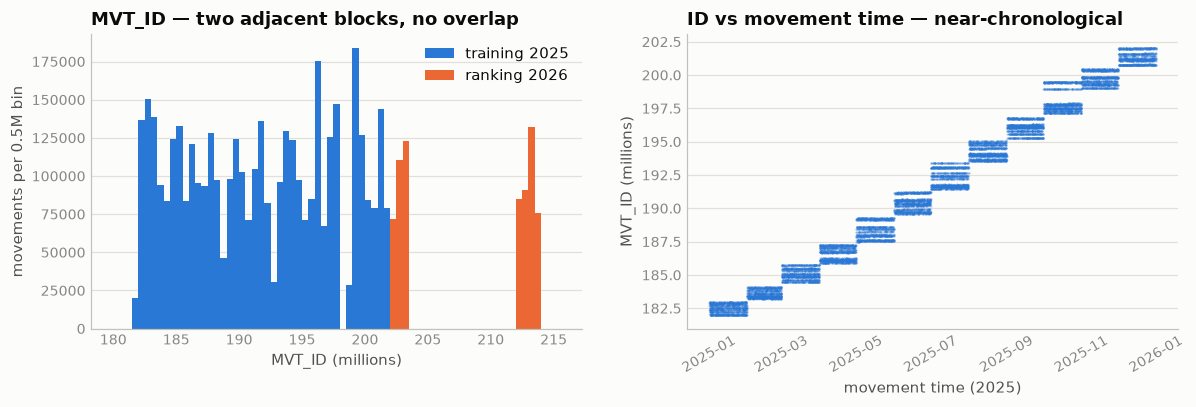

In [4]:
ids_t = con.sql(f"SELECT MVT_ID_mvt/1e6 v FROM {T}").df().v
ids_r = con.sql(f"SELECT MVT_ID_mvt/1e6 v FROM {R}").df().v
samp = con.sql(f"""SELECT MVT_TIME_UTC_mvt t, MVT_ID_mvt/1e6 v FROM {T}
                   USING SAMPLE reservoir(20000) REPEATABLE (42)""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.arange(180, 216, 0.5)
a1.hist(ids_t, bins=bins, color=BLUE, label="training 2025")
a1.hist(ids_r, bins=bins, color=ORANGE, label="ranking 2026")
a1.set_title("MVT_ID — two adjacent blocks, no overlap")
a1.set_xlabel("MVT_ID (millions)")
a1.set_ylabel("movements per 0.5M bin")
a1.legend()
style(a1)

a2.scatter(samp.t, samp.v, s=2, color=BLUE, alpha=0.25, linewidths=0)
a2.set_title("ID vs movement time — near-chronological")
a2.set_xlabel("movement time (2025)")
a2.set_ylabel("MVT_ID (millions)")
a2.tick_params(axis="x", rotation=30)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- All values are unique whole numbers, never null — in both files. Treat as an `int64` key.
- Ranking IDs (202.2M–213.8M) sit **entirely above** training's (182.0M–202.1M); zero overlap,
  and `submitting.parquet` is exactly the ranking departures' ID set. Within ranking, Jan and
  Jul 2026 form two separate ID blocks (~202–204M and ~212–214M) — IDs kept ticking through the
  months we don't see.
- IDs are handed out in near time order (rank corr ≈ 0.99 with movement time), in monthly
  batches — the scatter shows a staircase, with adjacent months' ID ranges overlapping. A few
  early-2025 rows carry IDs from ranges otherwise belonging to late 2025 (January's max ID is
  ≈ 202.06M, close to December's) — records reprocessed long after the fact.
- **Use in modeling: none** — it's a join key. Any signal it carries is record-creation time,
  which we get directly and more honestly from the timestamp columns.

## 2 · `FLIGHT_ID_mvt` — the matched flight plan's serial number

Two different systems feed these files. Airports record **movements** (a plane pushed back, a
plane took off); EUROCONTROL's Network Manager (NM) records **flight plans**. This column holds
the ID of the NM flight that the movement was matched to — *when* that match succeeded. All the
`*_flt` columns to the right come along with this match.

One NM flight = one leg (say, Heathrow → CDG). So when **both** ends of a leg are challenge
airports, the same `FLIGHT_ID` legitimately appears on two rows: once as `DEP` at the origin,
once as `ARR` at the destination.

Things to check: how often is it missing (and is missing-ness structured?), the duplicate
pattern, and whether the training/ranking ID ranges are disjoint like `MVT_ID`'s were.

In [5]:
order_stats("FLIGHT_ID_mvt").style.format("{:,.0f}")

,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,"4,167,797","30,930","3,821,595","280,340,526","280,498,586","283,937,522","287,175,586","291,184,686","294,420,395","294,567,590"
ranking 2026,"689,534","6,692","631,919","294,555,620","294,595,907","295,178,090","301,566,458","302,233,972","302,935,620","302,958,437"


In [6]:
# structure of the non-null values
dup = con.sql(f"""
    SELECT cnt, count(*) n_ids FROM (
        SELECT FLIGHT_ID_mvt, count(*) cnt FROM {T}
        WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1)
    GROUP BY 1 ORDER BY 1""").df()
combos = con.sql(f"""
    SELECT phases, count(*) n_ids FROM (
        SELECT FLIGHT_ID_mvt, string_agg(PHASE_mvt, '+' ORDER BY PHASE_mvt) phases
        FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 HAVING count(*) = 2)
    GROUP BY 1 ORDER BY n_ids DESC""").df()
ades_ok, pairs = con.sql(f"""
    SELECT sum((d_ades = a_airport)::INT), count(*) FROM (
        SELECT max(CASE WHEN PHASE_mvt='DEP' THEN ADES_mvt END) d_ades,
               max(CASE WHEN PHASE_mvt='ARR' THEN ADES_mvt END) a_airport
        FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL
        GROUP BY FLIGHT_ID_mvt HAVING count(*) = 2 AND count(DISTINCT PHASE_mvt) = 2)""").fetchone()
xtab = con.sql(f"""
    SELECT FLIGHT_ID_mvt IS NULL id_null, CALLSIGN_flt IS NULL flt_block_null, count(*) n
    FROM {T} GROUP BY 1, 2 ORDER BY n DESC""").df()
vfr = con.sql(f"""
    SELECT count(*), count(*) FILTER (FLIGHT_ID_mvt IS NULL)
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V'""").fetchone()
shared = con.sql(f"""
    SELECT count(DISTINCT t.FLIGHT_ID_mvt)
    FROM {T} t JOIN {R} r ON t.FLIGHT_ID_mvt = r.FLIGHT_ID_mvt""").fetchone()[0]

print("appearances per non-null ID (training):")
print(dup.to_string(index=False))
print("\nphase combos of the twice-appearing IDs:")
print(combos.to_string(index=False))
print(f"\nDEP+ARR pairs where DEP's destination == ARR's airport: {ades_ok:,.0f} of {pairs:,} (same leg, both ends)")
print("\nFLIGHT_ID null vs whole _flt block null:")
print(xtab.to_string(index=False))
print(f"\nVFR departures: {vfr[0]:,} — unmatched: {vfr[1]:,} (all of them)")
print(f"FLIGHT_IDs appearing in BOTH training and ranking: {shared}")

appearances per non-null ID (training):
 cnt   n_ids
   1 3506323
   2  315272

phase combos of the twice-appearing IDs:
 phases  n_ids
ARR+DEP 315269
DEP+DEP      3

DEP+ARR pairs where DEP's destination == ARR's airport: 313,639 of 315,269 (same leg, both ends)

FLIGHT_ID null vs whole _flt block null:
 id_null  flt_block_null       n
   False           False 4129878
    True            True   30930
   False            True    6989

VFR departures: 2,930 — unmatched: 2,930 (all of them)
FLIGHT_IDs appearing in BOTH training and ranking: 4


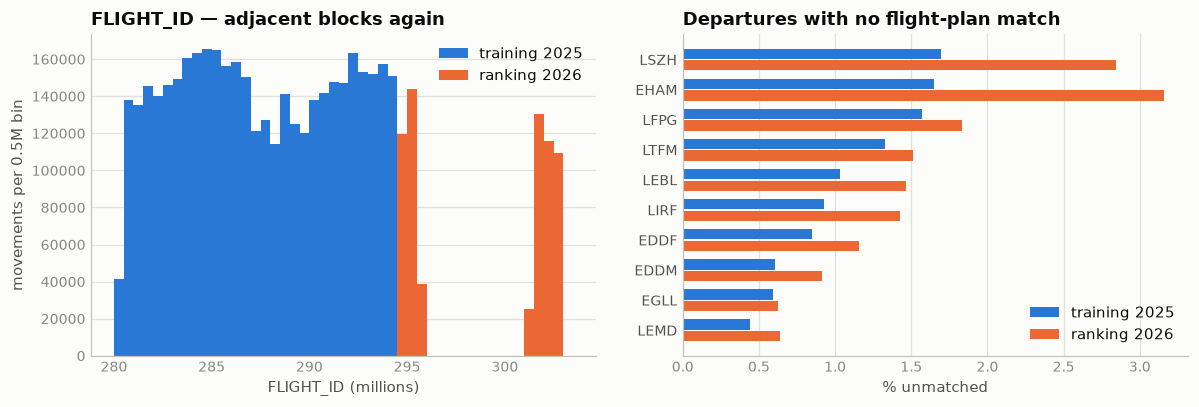

In [7]:
ids_t = con.sql(f"SELECT FLIGHT_ID_mvt/1e6 v FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL").df().v
ids_r = con.sql(f"SELECT FLIGHT_ID_mvt/1e6 v FROM {R} WHERE FLIGHT_ID_mvt IS NOT NULL").df().v
unm = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {T} WHERE PHASE_mvt='DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {R} WHERE PHASE_mvt='DEP' GROUP BY 1)
    SELECT t.a airport, t.pct pct_t, r.pct pct_r FROM t JOIN r ON t.a = r.a ORDER BY t.pct""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.arange(280, 304, 0.5)
a1.hist(ids_t, bins=bins, color=BLUE, label="training 2025")
a1.hist(ids_r, bins=bins, color=ORANGE, label="ranking 2026")
a1.set_title("FLIGHT_ID — adjacent blocks again")
a1.set_xlabel("FLIGHT_ID (millions)")
a1.set_ylabel("movements per 0.5M bin")
a1.legend()
style(a1)

y = np.arange(len(unm))
a2.barh(y + 0.19, unm.pct_t, height=0.34, color=BLUE, label="training 2025")
a2.barh(y - 0.19, unm.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a2.set_yticks(y, unm.airport, color=INK2)
a2.set_title("Departures with no flight-plan match")
a2.set_xlabel("% unmatched")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- Missing on 0.74% of training rows (DEP 1.08%, ARR 0.41%) and 0.97% of ranking rows (DEP
  1.53%) — when it's missing, the *entire* `_flt` block is empty. The reverse doesn't quite
  hold: 6,989 rows (almost all arrivals) carry a `FLIGHT_ID` yet still have an empty `_flt`
  block — matched, but the plan data didn't come through.
- **All 2,930 VFR departures are unmatched** — VFR flights don't file NM flight plans. Beyond
  those, unmatched share is highest at Zurich and Schiphol and peaks in summer (general-aviation
  season): missing-ness is *structured*, not random.
- 315,272 IDs appear on exactly two rows; 315,269 of those are a `DEP`+`ARR` pair, and for
  99.5% the departure's destination equals the arrival's airport — the **same leg seen from both
  challenge airports** (the rest are diversions/inconsistencies; 3 odd `DEP`+`DEP` cases).
- Ranking's ID block again sits above training's, but this time they touch: **4 IDs appear in
  both files** — overnight New Year's flights that departed Dec 31, 2025 (training) and landed
  Jan 1, 2026 (ranking). Confirms the files were split by movement date, not by flight.
- Unmatched IFR departures taxi slightly *longer* than matched ones (median 1,009 s vs 911 s);
  unmatched VFR ones much shorter (232 s).
- **Use in modeling:** the value itself is a join key (no signal beyond time). But (a) the
  **is-missing indicator** is a genuine feature — it flags VFR/GA traffic and rows where the
  `AOBT_3`-implied taxi feature won't exist; and (b) the DEP+ARR pairing may help engineered
  features later (linking a leg's two ends). Ranking's higher unmatched rate (1.53%) means the
  no-flight-plan fallback path matters slightly more at prediction time.